Данные загружены: 14980 строк, 14 признаков.

--- Perceptron ---
Точность: 0.5304

--- MLPClassifier (базовая) ---
Точность: 0.8518

--- Эксперименты ---

--- Итоговая таблица ---
Оптимизатор  Скорость обучения  Регуляризация  Точность
       adam              0.001          0.001    0.8485
       adam              0.001          0.010    0.8438
       adam              0.001          0.100    0.8231
       adam              0.010          0.001    0.8725
       adam              0.010          0.010    0.8621
       adam              0.010          0.100    0.8184
       adam              0.100          0.001    0.7850
       adam              0.100          0.010    0.7710
       adam              0.100          0.100    0.7453
        sgd              0.001          0.001    0.6976
        sgd              0.001          0.010    0.6966
        sgd              0.001          0.100    0.6903
        sgd              0.010          0.001    0.8421
        sgd              0.010      

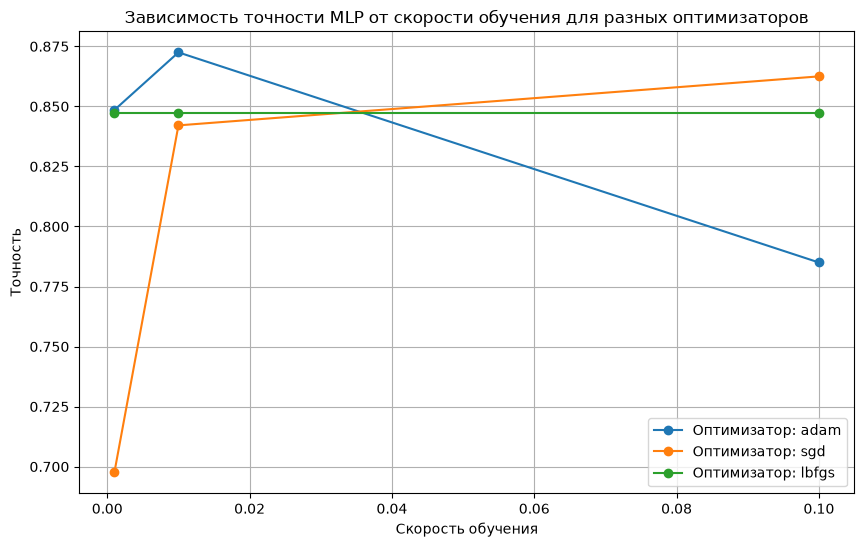

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import warnings
import time

warnings.filterwarnings('ignore')

# 1. Загрузка данных
data, meta = arff.loadarff('EEG Eye State.arff')
df = pd.DataFrame(data)
target_column = df.columns[-1]
df[target_column] = df[target_column].astype(int)
X = df.drop(target_column, axis=1)
y = df[target_column]
print(f"Данные загружены: {X.shape[0]} строк, {X.shape[1]} признаков.")

# 2. Разделение
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Perceptron
print("\n--- Perceptron ---")
perceptron = Perceptron(random_state=42, max_iter=1000)
perceptron.fit(X_train_scaled, y_train)
print(f"Точность: {accuracy_score(y_test, perceptron.predict(X_test_scaled)):.4f}")

# 5. Базовая модель MLP
print("\n--- MLPClassifier (базовая) ---")
mlp = MLPClassifier(hidden_layer_sizes=(30,), max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)
print(f"Точность: {accuracy_score(y_test, mlp.predict(X_test_scaled)):.4f}")

# 6. Эксперименты
print("\n--- Эксперименты ---")
solvers = ['adam', 'sgd', 'lbfgs']
learning_rates = [0.001, 0.01, 0.1]
alphas = [0.001, 0.01, 0.1]

results = []
total = len(solvers) * len(learning_rates) * len(alphas)
counter = 0

for solver in solvers:
    for lr in learning_rates:
        for alpha in alphas:
            counter += 1
            start = time.time()
            
            model = MLPClassifier(
                hidden_layer_sizes=(30,),
                solver=solver,
                learning_rate_init=lr,
                alpha=alpha,
                max_iter=300,
                random_state=42
            )
            model.fit(X_train_scaled, y_train)
            score = model.score(X_test_scaled, y_test)
            
            results.append({
                'Оптимизатор': solver,
                'Скорость обучения': lr,
                'Регуляризация': alpha,
                'Точность': round(score, 4)
            })

# 7. Результаты
results_df = pd.DataFrame(results)
print("\n--- Итоговая таблица ---")
print(results_df.to_string(index=False))

best = results_df.loc[results_df['Точность'].idxmax()]
print(f"\nЛучшая комбинация: {best.to_dict()}")

# 8. График
plt.figure(figsize=(10, 6))
alpha_fixed = 0.001
for solver in solvers:
    subset = results_df[(results_df['Оптимизатор'] == solver) & (results_df['Регуляризация'] == alpha_fixed)]
    if not subset.empty:
        plt.plot(subset['Скорость обучения'], subset['Точность'], marker='o', label=f'Оптимизатор: {solver}')

plt.title('Зависимость точности MLP от скорости обучения для разных оптимизаторов')
plt.xlabel('Скорость обучения')
plt.ylabel('Точность')
plt.legend()
plt.grid(True)
plt.show()